In [3]:
import os
import cv2
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# --- CONFIGURATION ---
# Pick ONE image and annotation pair to test the pipeline visually
IMG_PATH = "../data/raw/Images/Agora_I_4985_Rotation1_300dpi.png" # Update with your file
ANN_PATH = "../data/raw/Annotations/Agora_I_4985_Rotation1_300dpi_letters.txt" # Update with your file

print(f"Testing Image: {os.path.basename(IMG_PATH)}")

Testing Image: Agora_I_4985_Rotation1_300dpi.png


Total Boxes Found: 88
Total Transcript Lines Found: 13


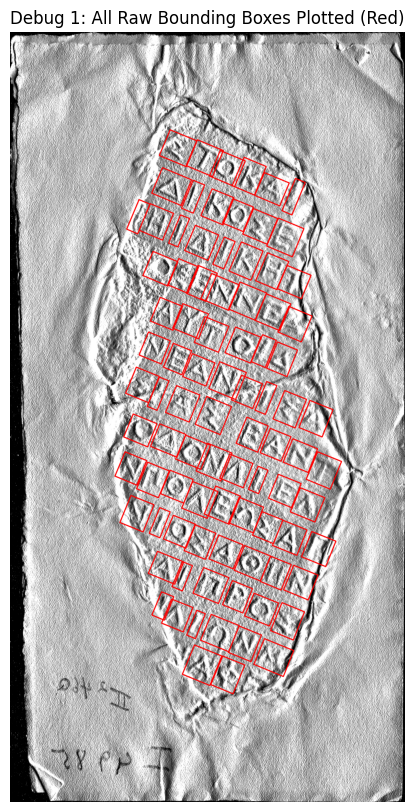

In [4]:
def load_raw_data(file_path):
    with open(file_path, 'r', encoding='utf-8') as f:
        lines = f.readlines()

    boxes = []
    transcript_start_idx = -1

    for i, line in enumerate(lines):
        if line.strip().startswith("# Boxes"):
            j = i + 1
            while j < len(lines):
                if lines[j].strip().startswith("# Transcript"):
                    transcript_start_idx = j + 1
                    break
                parts = lines[j].strip().split()
                if len(parts) == 8:
                    try:
                        c = [float(p) for p in parts]
                        poly = np.array([[c[0], c[1]], [c[2], c[3]], [c[4], c[5]], [c[6], c[7]]], dtype=np.float32)
                        boxes.append(poly)
                    except ValueError: pass
                j += 1
            break

    raw_transcripts = []
    if transcript_start_idx != -1:
        for i in range(transcript_start_idx, len(lines)):
            line_content = lines[i].strip()
            if line_content.startswith("# Lines"): break
            if line_content: raw_transcripts.append(line_content)

    return boxes, raw_transcripts

boxes, raw_transcripts = load_raw_data(ANN_PATH)
print(f"Total Boxes Found: {len(boxes)}")
print(f"Total Transcript Lines Found: {len(raw_transcripts)}")

# --- DEBUG VISUALIZATION 1: Raw Boxes ---
img = cv2.imread(IMG_PATH)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
vis_img = img_rgb.copy()

for box in boxes:
    pts = np.int32(box)
    cv2.polylines(vis_img, [pts], isClosed=True, color=(255, 0, 0), thickness=3)

plt.figure(figsize=(15, 10))
plt.imshow(vis_img)
plt.title("Debug 1: All Raw Bounding Boxes Plotted (Red)")
plt.axis('off')
plt.show()

Successfully grouped into 13 lines.


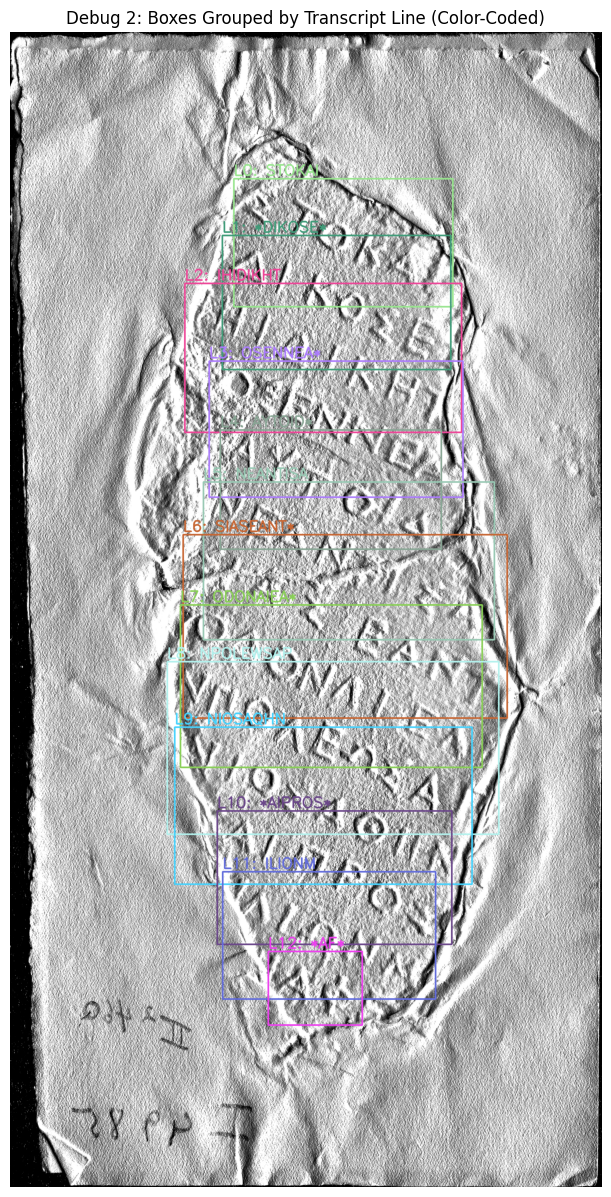

In [5]:
line_data = []
box_index = 0

for raw_text in raw_transcripts:
    clean_text = "".join([c for c in raw_text if c not in (' ', '\t')])
    chars_with_boxes = [c for c in clean_text if c != '*']
    num_boxes_to_consume = len(chars_with_boxes)
    
    if num_boxes_to_consume == 0: continue
        
    line_boxes = boxes[box_index : box_index + num_boxes_to_consume]
    box_index += num_boxes_to_consume
    
    if not line_boxes: continue

    all_points = np.vstack(line_boxes) 
    line_data.append({'text': clean_text, 'points': all_points})

print(f"Successfully grouped into {len(line_data)} lines.")

# --- DEBUG VISUALIZATION 2: Grouped Lines ---
vis_img2 = img_rgb.copy()
np.random.seed(42) # For consistent colors

for i, line in enumerate(line_data):
    color = tuple(np.random.randint(50, 255, 3).tolist()) # Random bright color
    pts = np.int32(line['points'])
    
    # Get bounding rect just for visualization purposes here
    x, y, w, h = cv2.boundingRect(pts)
    cv2.rectangle(vis_img2, (x, y), (x+w, y+h), color, 4)
    
    # Put the target text above the line
    cv2.putText(vis_img2, f"L{i}: {line['text']}", (x, max(10, y - 10)), 
                cv2.FONT_HERSHEY_SIMPLEX, 1.5, color, 4)

plt.figure(figsize=(15, 15))
plt.imshow(vis_img2)
plt.title("Debug 2: Boxes Grouped by Transcript Line (Color-Coded)")
plt.axis('off')
plt.show()

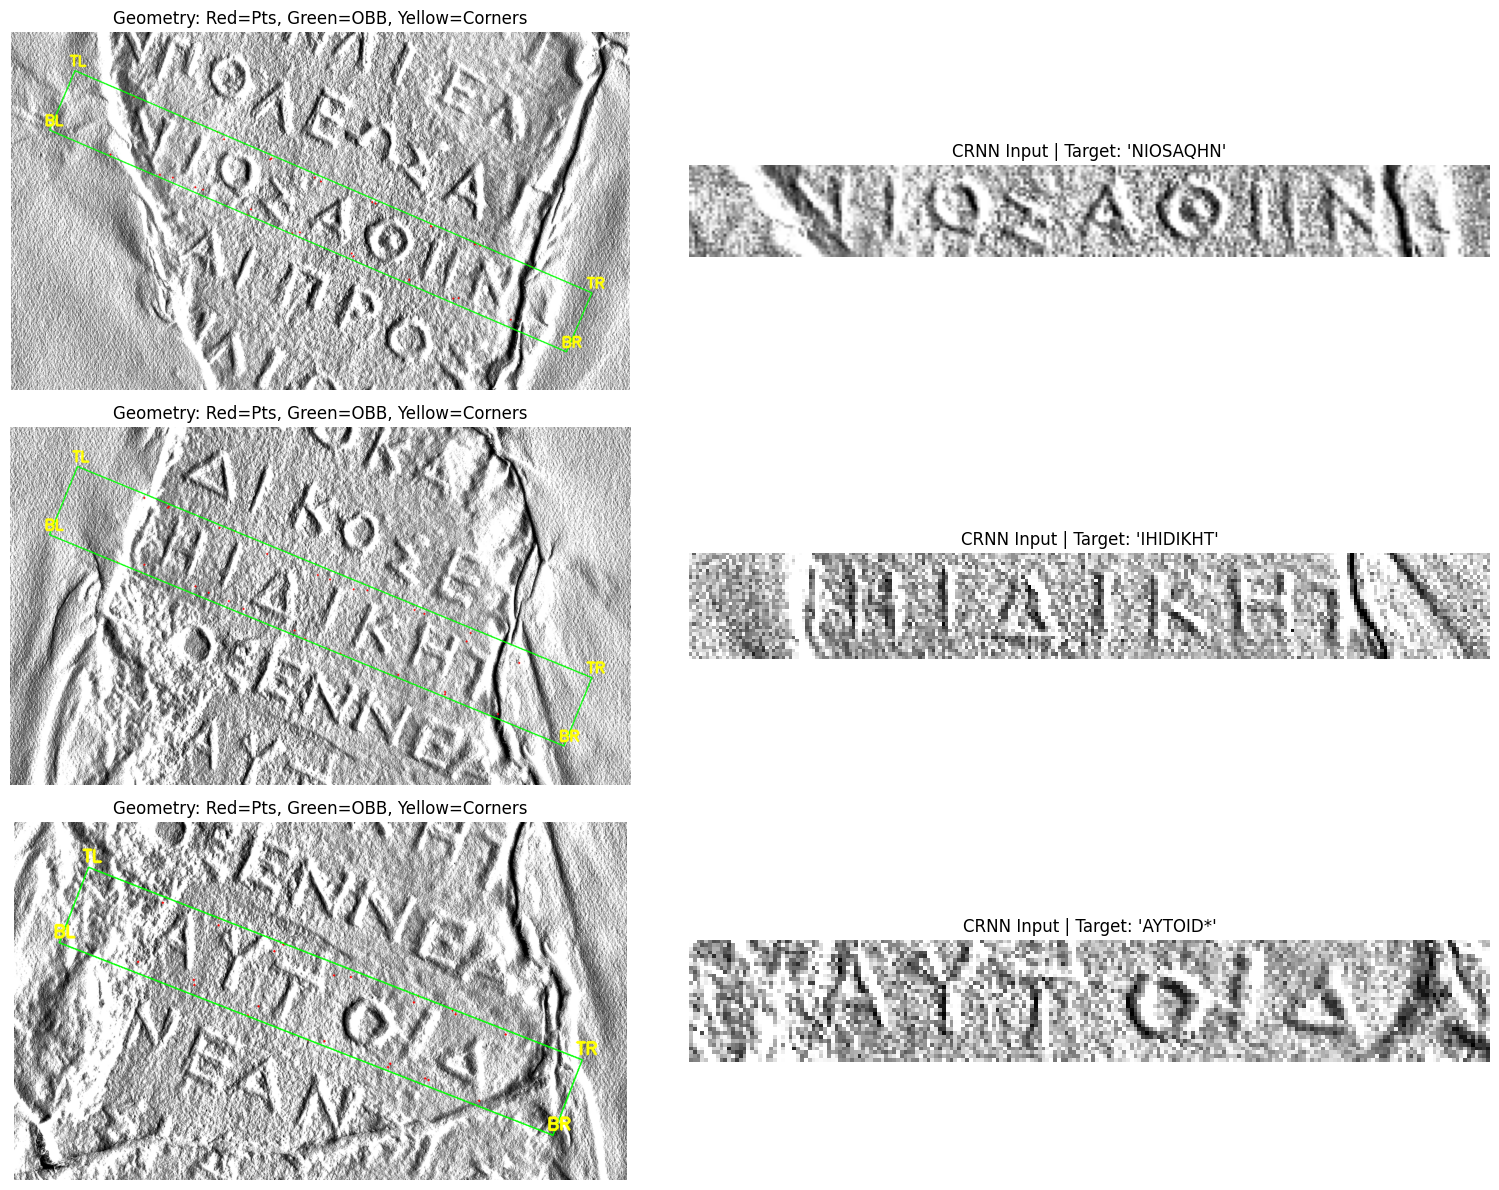

In [6]:
def order_points(pts):
    rect = np.zeros((4, 2), dtype="float32")
    s = pts.sum(axis=1)
    rect[0] = pts[np.argmin(s)] # TL
    rect[2] = pts[np.argmax(s)] # BR
    diff = np.diff(pts, axis=1)
    rect[1] = pts[np.argmin(diff)] # TR
    rect[3] = pts[np.argmax(diff)] # BL
    return rect

NUM_SAMPLES = 3
samples = random.sample(line_data, min(NUM_SAMPLES, len(line_data)))

fig, axs = plt.subplots(len(samples), 2, figsize=(16, 4 * len(samples)))
if len(samples) == 1: axs = [axs]

for idx, test_line in enumerate(samples):
    pts = test_line['points']
    rect = cv2.minAreaRect(pts)
    (cx, cy), (w, h), angle = rect

    if h > w:
        w, h = h, w
        angle -= 90.0

    # +T Padding
    extension = int(h) # Force full padding for clear visualization
    padded_w = w + (2 * extension)
    padded_rect = ((cx, cy), (padded_w, h), angle)
    box = cv2.boxPoints(padded_rect)
    src_pts = order_points(box)

    # Warp
    target_h = 32
    target_w = max(1, int(padded_w * (target_h / max(1, h))))
    dst_pts = np.array([[0,0], [target_w-1, 0], [target_w-1, target_h-1], [0, target_h-1]], dtype="float32")
    
    M = cv2.getPerspectiveTransform(src_pts, dst_pts)
    warped_crop = cv2.warpPerspective(img_rgb, M, (target_w, target_h), borderValue=(0,0,0))

    # --- DEBUG VISUALIZATION 3: OBB Geometry ---
    vis_img3 = img_rgb.copy()
    box_int = np.int32(box)
    
    # Draw original character points
    for p in pts: cv2.circle(vis_img3, (int(p[0]), int(p[1])), 2, (255, 0, 0), -1)
    
    # Draw padded OBB
    cv2.drawContours(vis_img3, [box_int], 0, (0, 255, 0), 2)
    
    # Draw Corner Labels to verify order_points
    corner_labels = ['TL', 'TR', 'BR', 'BL']
    for i, p in enumerate(src_pts):
        cv2.putText(vis_img3, corner_labels[i], (int(p[0])-10, int(p[1])-10), 
                    cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 255, 0), 3)

    # Zoom in
    x_coords, y_coords = [p[0] for p in box_int], [p[1] for p in box_int]
    pad = 80
    v_x1, v_x2 = max(0, int(min(x_coords)) - pad), min(img.shape[1], int(max(x_coords)) + pad)
    v_y1, v_y2 = max(0, int(min(y_coords)) - pad), min(img.shape[0], int(max(y_coords)) + pad)

    axs[idx][0].imshow(vis_img3[v_y1:v_y2, v_x1:v_x2])
    axs[idx][0].set_title(f"Geometry: Red=Pts, Green=OBB, Yellow=Corners")
    axs[idx][0].axis('off')

    axs[idx][1].imshow(warped_crop)
    axs[idx][1].set_title(f"CRNN Input | Target: '{test_line['text']}'")
    axs[idx][1].axis('off')

plt.tight_layout()
plt.show()


Batch Tensor Shape: torch.Size([5, 1, 32, 251]) (Batch, Channel, Height, Max_Width)


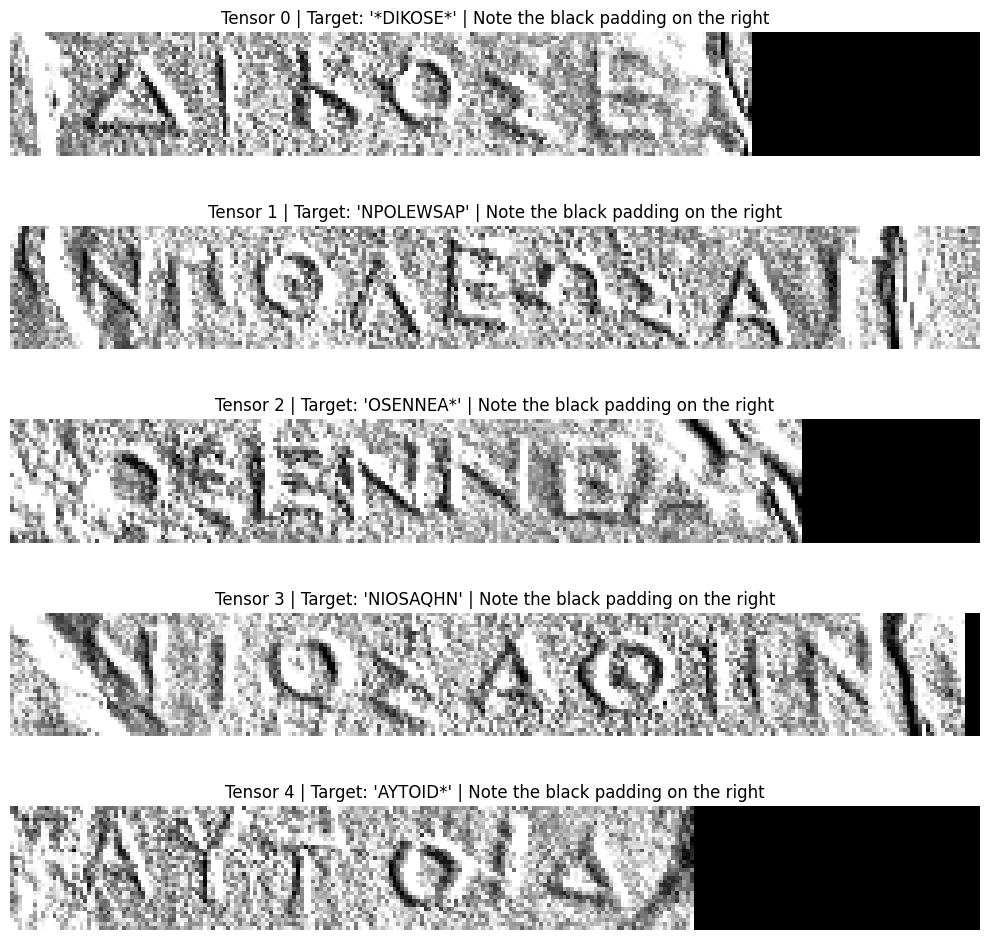

In [7]:
# 1. Build Vocab
unique_chars = set()
for d in line_data: unique_chars.update(list(d['text']))
chars = sorted(list(unique_chars))
char2idx = {char: idx + 1 for idx, char in enumerate(chars)}
idx2char = {idx + 1: char for idx, char in enumerate(chars)}

# 2. Simulate Dataset Output (Normally this reads from disk)
dataset_sim = []
for line in line_data:
    # Re-warp to grayscale for the network
    pts, text = line['points'], line['text']
    rect = cv2.minAreaRect(pts)
    (cx, cy), (w, h), angle = rect
    if h > w: w, h, angle = h, w, angle - 90.0
    padded_w = w + h 
    box = cv2.boxPoints(((cx, cy), (padded_w, h), angle))
    src_pts = order_points(box)
    
    target_h = 32
    target_w = max(1, int(padded_w * (target_h / max(1, h))))
    dst_pts = np.array([[0,0], [target_w-1, 0], [target_w-1, target_h-1], [0, target_h-1]], dtype="float32")
    M = cv2.getPerspectiveTransform(src_pts, dst_pts)
    
    img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    crop = cv2.warpPerspective(img_gray, M, (target_w, target_h), borderValue=0)
    
    # Normalize to [-1, 1]
    img_tensor = torch.FloatTensor((crop / 127.5) - 1.0).unsqueeze(0)
    target = [char2idx[c] for c in text]
    dataset_sim.append((img_tensor, target, text))

# 3. Collate Function
def crnn_collate_fn(batch):
    images, targets, raw_texts = zip(*batch)
    max_width = max([img.shape[2] for img in images])
    
    padded_images = []
    for img in images:
        pad_amount = max_width - img.shape[2]
        padded_img = F.pad(img, (0, pad_amount, 0, 0), value=-1.0)
        padded_images.append(padded_img)
        
    return torch.stack(padded_images), raw_texts

# --- DEBUG VISUALIZATION 4: The PyTorch Batch ---
loader = DataLoader(dataset_sim, batch_size=5, shuffle=True, collate_fn=crnn_collate_fn)
batch_images, batch_texts = next(iter(loader))

print(f"Batch Tensor Shape: {batch_images.shape} (Batch, Channel, Height, Max_Width)")

fig, axs = plt.subplots(len(batch_images), 1, figsize=(10, 2 * len(batch_images)))
for i in range(len(batch_images)):
    # Un-normalize tensor back to [0, 255] for plotting
    img_plot = ((batch_images[i].squeeze(0).numpy() + 1.0) * 127.5).astype(np.uint8)
    axs[i].imshow(img_plot, cmap='gray')
    axs[i].set_title(f"Tensor {i} | Target: '{batch_texts[i]}' | Note the black padding on the right")
    axs[i].axis('off')

plt.tight_layout()
plt.show()

In [11]:
import os
import cv2
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction

# --- CONFIGURATION ---
TEST_IMAGE = "../data/raw/Images/Agora_I_4985_Rotation1_300dpi.png" # Pick a test image
YOLO_MODEL_PATH = "../runs/obb/train/weights/best.pt"             # Update to your YOLO weights
CRNN_MODEL_PATH = "../models/crnn_greek_20260420_155707_best.pth" # Update to your best CRNN weights
LABELS_FILE = "../data/processed/crnn_training_data/labels.txt"             # Used to rebuild vocab

# data/processed/crnn_training_data/labels.txt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# --- REBUILD EXACT VOCABULARY ---
unique_chars = set()
with open(LABELS_FILE, "r", encoding="utf-8") as f:
    for line in f:
        parts = line.strip().split('\t')
        if len(parts) == 2:
            unique_chars.update(list(parts[1]))

chars = sorted(list(unique_chars))
char2idx = {char: idx + 1 for idx, char in enumerate(chars)}
idx2char = {idx + 1: char for idx, char in enumerate(chars)}

print(f"Loaded Vocabulary: {len(chars)} characters + 1 Blank")

Using device: cpu
Loaded Vocabulary: 28 characters + 1 Blank
